# Quantifying response to volcanic eruptions

In [59]:
import cfr
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cftime


In [60]:
volcanic_year = 1816
rolling_window = 3

## LMRv2.1

In [61]:
res = cfr.ReconRes('./recons/lmr_reproduce_pda_ptype_res/')
res.load(['tas', 'tas_gm', 'pr', 'pr_gm'])

In [62]:
lmr_tas = res.recons['tas']
lmr_pr = res.recons['pr']


In [63]:
# Rolling means
lmr_tas_rolling = lmr_tas.da.rolling(time=rolling_window, center=False).mean()
lmr_pr_rolling = lmr_pr.da.rolling(time=rolling_window, center=False).mean()

In [64]:
erup_time_idx = np.where(lmr_tas.da.time == volcanic_year)[0][0]

In [65]:
# Get volcanic year data and subtract rolling mean from previous year
lmr_tas_volcanic_year = lmr_tas.da.isel(time=erup_time_idx) - lmr_tas_rolling.isel(time=erup_time_idx-1)
lmr_pr_volcanic_year = lmr_pr.da.isel(time=erup_time_idx) - lmr_pr_rolling.isel(time=erup_time_idx-1)

In [66]:
lmr_volcanic = cfr.ClimateField()
lmr_volcanic.da = lmr_tas_volcanic_year

lmr_volcanic.da.name = 'air'

In [67]:
lmr_volcanic_p = cfr.ClimateField()
lmr_volcanic_p.da = lmr_pr_volcanic_year

lmr_volcanic_p.da.name = 'pr'

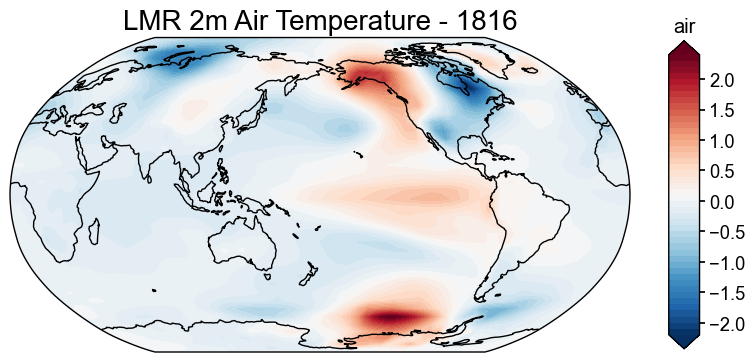

In [68]:
fig, ax = lmr_volcanic.plot(title=f"LMR 2m Air Temperature - {volcanic_year}", cmap='RdBu_r')


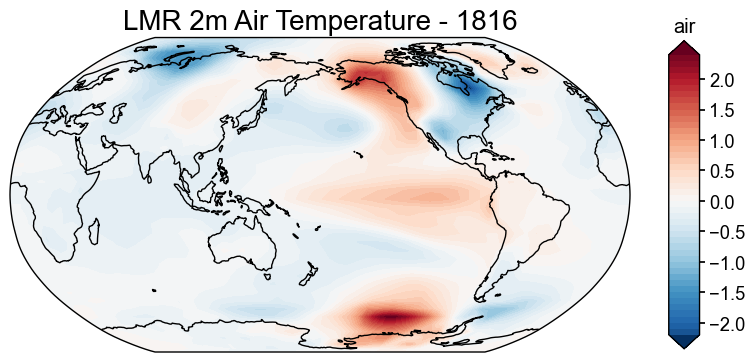

In [69]:
fig, ax = lmr_volcanic.plot(title=f"LMR 2m Air Temperature - {volcanic_year}", 
                            cmap='RdBu_r', clim=(-2.5, 2.5))

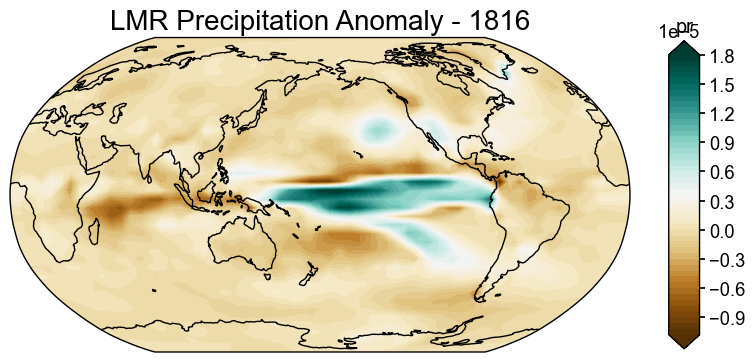

In [70]:
fig, ax = lmr_volcanic_p.plot(title=f"LMR Precipitation Anomaly - {volcanic_year}", cmap='BrBG')

## PReSto2k

In [71]:
res2 = cfr.ReconRes('./recons/lmr_reproduce_lipd/')
res2.load(['tas', 'tas_gm', 'pr', 'pr_gm'])

In [72]:
presto_tas = res2.recons['tas']
presto_pr = res2.recons['pr']

In [73]:
presto_tas_rolling = presto_tas.da.rolling(time=rolling_window, center=False).mean()
presto_pr_rolling = presto_pr.da.rolling(time=rolling_window, center=False).mean()

In [74]:
erup_time_idx = np.where(presto_tas.da.time == volcanic_year)[0][0]

In [75]:
# Get volcanic year data and subtract rolling mean from previous year
presto_tas_volcanic_year = presto_tas.da.isel(time=erup_time_idx) - presto_tas_rolling.isel(time=erup_time_idx-1)
presto_pr_volcanic_year = presto_pr.da.isel(time=erup_time_idx) - presto_pr_rolling.isel(time=erup_time_idx-1)

In [76]:
presto_volcanic = cfr.ClimateField()
presto_volcanic.da = presto_tas_volcanic_year

presto_volcanic.da.name = 'air'

In [77]:
presto_volcanic_p = cfr.ClimateField()
presto_volcanic_p.da = presto_pr_volcanic_year

presto_volcanic_p.da.name = 'pr'

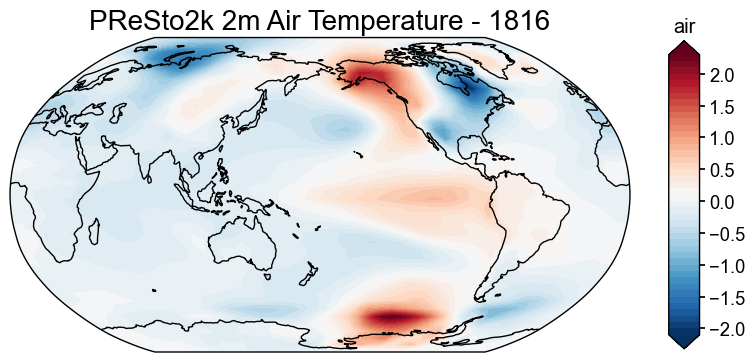

In [78]:
fig, ax = presto_volcanic.plot(title=f"PReSto2k 2m Air Temperature - {volcanic_year}", cmap='RdBu_r')

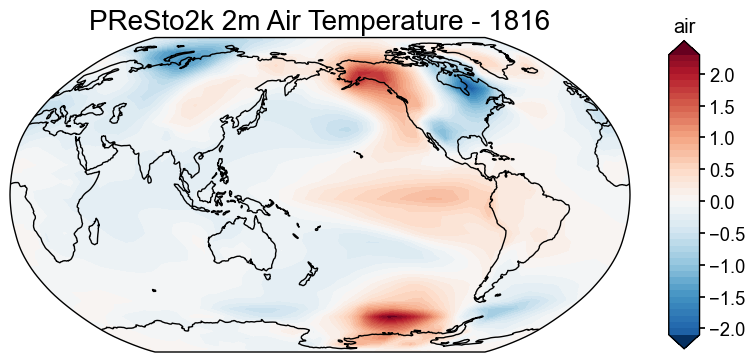

In [79]:
fig, ax = presto_volcanic.plot(title=f"PReSto2k 2m Air Temperature - {volcanic_year}", 
                            cmap='RdBu_r', clim=(-2.5, 2.5))

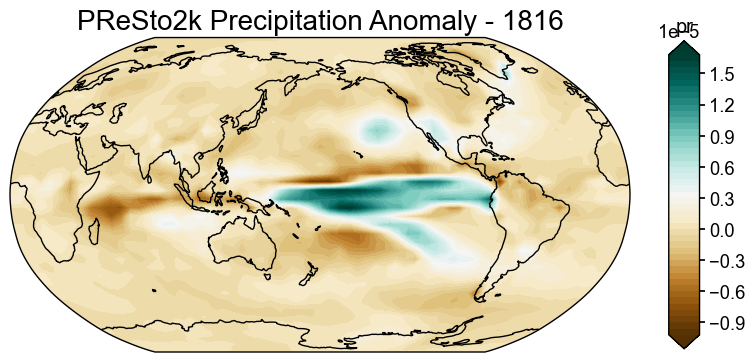

In [80]:
fig, ax = presto_volcanic_p.plot(title=f"PReSto2k Precipitation Anomaly - {volcanic_year}", cmap='BrBG')

## DOCU-CLIM

In [81]:
res3 = cfr.ReconRes('./recons/docu_clim_tas_pda/')
res3.load(['tas', 'tas_gm'])

In [82]:
res4 = cfr.ReconRes('./recons/docu_clim_pr_pda/')
res4.load(['pr','pr_gm'])

In [83]:
docu_tas = res3.recons['tas']
docu_pr = res4.recons['pr']

In [84]:
docu_tas_rolling = docu_tas.da.rolling(time=rolling_window, center=False).mean()
docu_pr_rolling = docu_pr.da.rolling(time=rolling_window, center=False).mean()

In [85]:
erup_time_idx = np.where(docu_tas.da.time == volcanic_year)[0][0]

In [86]:
erup_time_idx_p = np.where(docu_pr.da.time == volcanic_year)[0][0]

In [87]:
docu_tas_volcanic_year = docu_tas.da.isel(time=erup_time_idx) - docu_tas_rolling.isel(time=erup_time_idx-1)
docu_pr_volcanic_year = docu_pr.da.isel(time=erup_time_idx_p) - docu_pr_rolling.isel(time=erup_time_idx_p-1)

In [88]:
docu_volcanic = cfr.ClimateField()
docu_volcanic.da = docu_tas_volcanic_year

docu_volcanic.da.name = 'air'

In [89]:
docu_volcanic_p = cfr.ClimateField()
docu_volcanic_p.da = docu_pr_volcanic_year

docu_volcanic_p.da.name = 'pr'

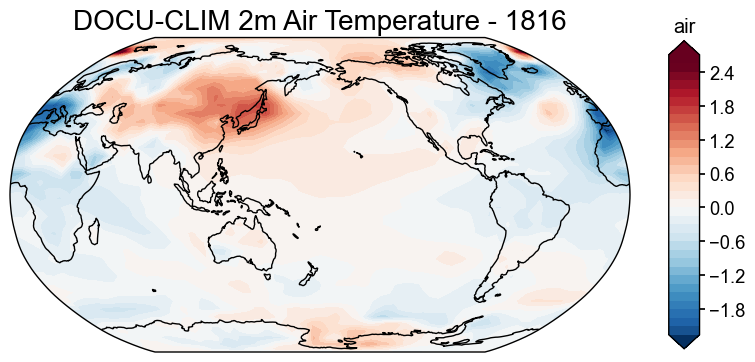

In [90]:
#fig, ax = docu_volcanic.plot(title=f"DOCU-CLIM 2m Air Temperature - {volcanic_year}", cmap='RdBu_r')

fig, ax = docu_volcanic.plot(title=f"DOCU-CLIM 2m Air Temperature - {volcanic_year}", 
                            cmap='RdBu_r', clim=(-2.5, 2.5))

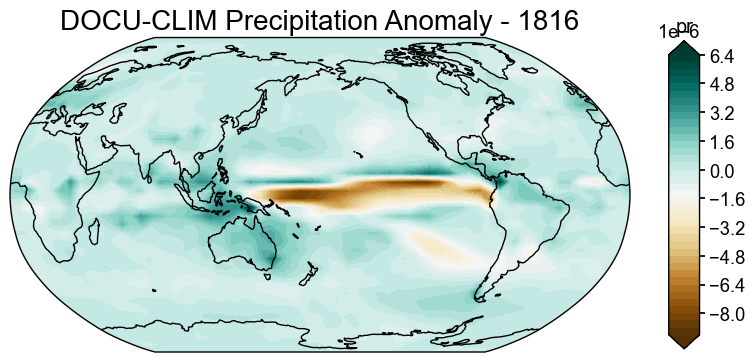

In [91]:
fig, ax = docu_volcanic_p.plot(title=f"DOCU-CLIM Precipitation Anomaly - {volcanic_year}", 
                            cmap='BrBG')

## Comparing

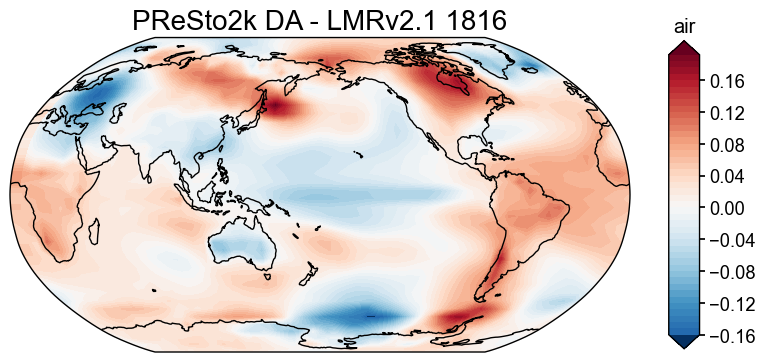

In [101]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = (presto_volcanic - lmr_volcanic).plot(
    title='PReSto2k DA - LMRv2.1 1816', 
    cmap='RdBu_r', 
    clim=(-0.2, 0.2)
)


(<Figure size 1000x800 with 2 Axes>,
 <GeoAxes: title={'center': 'PReSto2k DA - LMRv2.1 1816'}>)

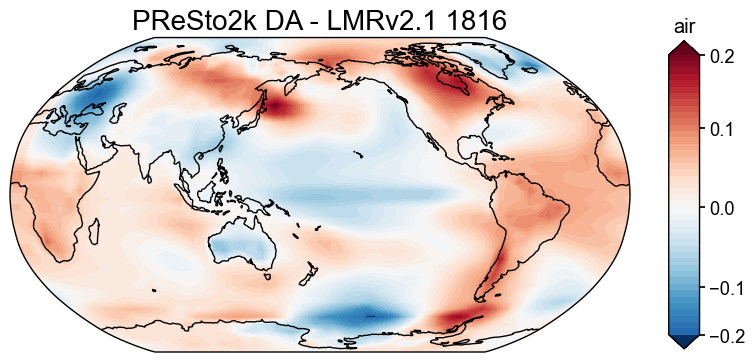

In [105]:
import numpy as np

(presto_volcanic - lmr_volcanic).plot(
    title='PReSto2k DA - LMRv2.1 1816', 
    cmap='RdBu_r', 
    clim=(-0.2, 0.2),
    cbar_labels=[-0.2, -0.1, 0.0, 0.1, 0.2]  # Just 5 clean values
)

In [93]:
ts_p = res2.recons['tas_gm'] 
ts_l = res.recons['tas_gm'
                  ]

(<Figure size 1200x400 with 1 Axes>,
 <Axes: title={'center': 'PReSto2k DA - LMRv2.1 GMST'}, xlabel='Year (CE)', ylabel='tas_gm'>)

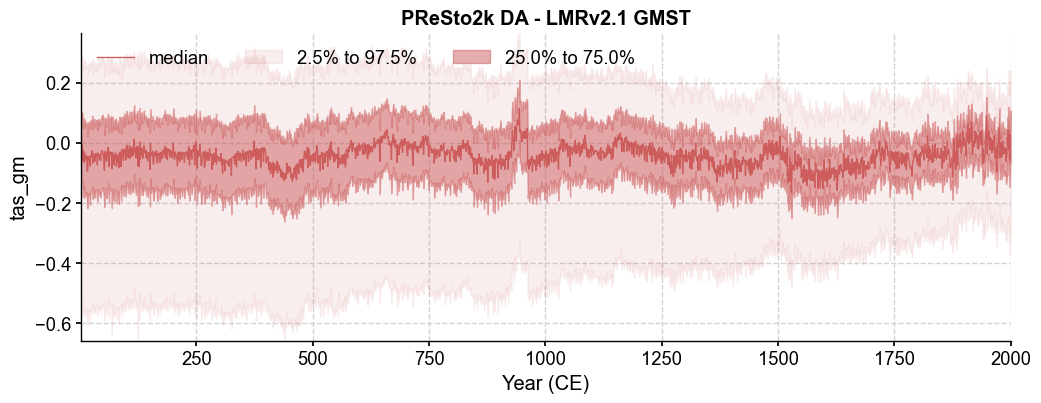

In [94]:
(ts_p-ts_l).plot_qs(title='PReSto2k DA - LMRv2.1 GMST')

In [ ]:
def get_volcanic_field(field, yr, name):
    tas = field.recons['tas']

    # 3 year pre-eruption baseline
    baseline = tas.da.sel(time=slice(yr-3, yr-1)).mean(dim='time')

    # Get volcanic period (1816-1817 composite)
    volcanic_period = tas.da.sel(time=slice(yr+1,yr+2)).mean(dim='time')

    # Subtract baseline to get volcanic response
    tas_volcanic = volcanic_period - baseline

    volcanic = cfr.ClimateField()
    volcanic.da = tas_volcanic
    volcanic.da.name = 'air'

    fig, ax = volcanic.plot(title=f"{name} {yr+1} Relative to 3 year Pre-Eruption Baseline ", cmap='RdBu_r',
                            levels=np.linspace(-2, 2, 21),       # set levels for the colors
    cbar_labels=np.linspace(-2, 2, 11))
    plt.tight_layout()

    return volcanic

In [ ]:
fig, ax = plt.subplots(figsize=(10,4))
res_ts = res_lmr.recons['tas_gm']
res_ts.plot_qs(ax=ax, xlim=(1550, 1650), title='LMR Rerproduced (1550–1650)')
ax.grid(True, alpha=0.3)
ax.set_ylabel('GMSTa (°C)')
ax.axvline(x=1601.0, color='black', linestyle='--', linewidth=0.7)

median_ts = res_ts.median        
imin = np.nanargmin(median_ts)
t_min_median = res_ts.time[imin]
v_min_median = median_ts[imin]
print(f"Minimum: {v_min_median:.3f} at year {t_min_median:.1f}")